# Inspect saved injections

View representative injected light curves beside their original controls and the
isolated signal actually added. This notebook reads completed evaluation results;
it does not regenerate signals, run classifiers, or validate dependency internals.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'searchlight').is_dir())
sys.path.insert(0, str(ROOT))
from searchlight.evaluation.preprocessing import read_lightcurve

RUN = ROOT / 'evaluation_runs/full-evaluation'
MAX_CASES = 6
AMPLITUDES_PPM = (100, 1000, 10000)
SEED = 42

completed = [p for p in [RUN, *RUN.parent.glob(RUN.name+'-[0-9][0-9][0-9]*')]
             if (p/'complete.json').is_file()]
if not completed:
    raise RuntimeError('Set RUN to a completed evaluation.')
RUN = max(completed, key=lambda p: (p/'complete.json').stat().st_mtime_ns)
RESULTS = RUN / 'results'
manifest = json.loads((RESULTS/'manifest.json').read_text())
events = json.loads((RESULTS/'event_details.json').read_text())
samples = {s['sample_id']: s for s in manifest['samples']}
print('Reading saved curves from:', RUN)


Reading saved curves from: /home/anm1u24/Code/astrosearchlight/evaluation_runs/full-evaluation-002


## Select examples

Choose observable test events across the requested amplitudes, using a fixed seed
and at most one example per parent control. Change the settings above to inspect
other levels. Selection here is for visual inspection, not a performance estimate.


In [2]:
rng = np.random.default_rng(SEED)
pool = [e for e in events if e['split']=='test' and e['observable']
        and samples[e['sample_id']].get('parent_id')]
available = sorted({e['amplitude']*1e6 for e in pool})
if not available:
    raise RuntimeError('No observable test injections in this run.')
levels = sorted({min(available, key=lambda x: abs(np.log(x/level))) for level in AMPLITUDES_PPM})
candidates = {level: list(rng.permutation([e for e in pool if np.isclose(e['amplitude']*1e6, level)]))
              for level in levels}
selected, parents = [], set()
while len(selected) < MAX_CASES:
    before = len(selected)
    for level in levels:
        while candidates[level]:
            event = candidates[level].pop()
            sample = samples[event['sample_id']]
            if sample['parent_id'] not in parents:
                selected.append(event)
                parents.add(sample['parent_id'])
                break
        if len(selected) >= MAX_CASES:
            break
    if len(selected) == before:
        break
cases, inventory = [], []
for event in selected:
    sample = samples[event['sample_id']]
    injected = read_lightcurve(sample['source'])
    control = read_lightcurve(samples[sample['parent_id']]['source'])
    for field in ('time', 'quality', 'exposure_seconds', 'flux_err'):
        np.testing.assert_array_equal(getattr(control, field), getattr(injected, field))
    finite = np.isfinite(control.time) & np.isfinite(control.flux) & np.isfinite(injected.flux)
    baseline = float(np.median(control.flux[finite]))
    added_ppm = (injected.flux-control.flux)/baseline*1e6
    cases.append((event, sample, control, injected, finite, baseline, added_ppm))
    params = sample['parameters'].get('physical_parameters', {})
    inventory.append(dict(sample_id=sample['sample_id'], amplitude_ppm=event['amplitude']*1e6,
        source_mass=params.get('Mcomp'), lens_mass=params.get('Macc'),
        period_days=params.get('period_days'), fwhm_days=event['duration_days'],
        coverage_fraction=event['coverage_fraction'], structural_columns_unchanged=True))
display(pd.DataFrame(inventory))


,sample_id,amplitude_ppm,source_mass,lens_mass,period_days,fwhm_days,coverage_fraction,structural_columns_unchanged
0,tic307216507-sector39-cadence120-shape6-amp1,100.0,31.230083,0.729889,10.816693,0.816933,0.990023,True
1,tic89964888-sector13-cadence120-shape2-amp3,1000.0,4.827586,1.960080,35.052767,0.440805,0.988434,True
2,tic277707804-sector13-cadence120-shape1-amp5,10000.0,29.159383,5.328742,2871.148889,4.997880,0.765532,True
3,tic468149996-sector39-cadence120-shape6-amp1,100.0,16.322451,1.148078,116.883756,0.946063,0.684120,True
4,tic383063273-sector39-cadence120-shape4-amp3,1000.0,26.409440,1.033943,2.752591,0.471758,0.990000,True
5,tic167201200-sector13-cadence120-shape7-amp5,10000.0,44.300273,11.741928,5.834340,0.633393,0.916196,True


## Controls, injected curves, and added signals

Left: the full observation. Middle: a close-up around the declared event peak.
Right: injected minus control flux, normalized by the control median. The curves
are the saved inputs used by the evaluation, including their original cadences.


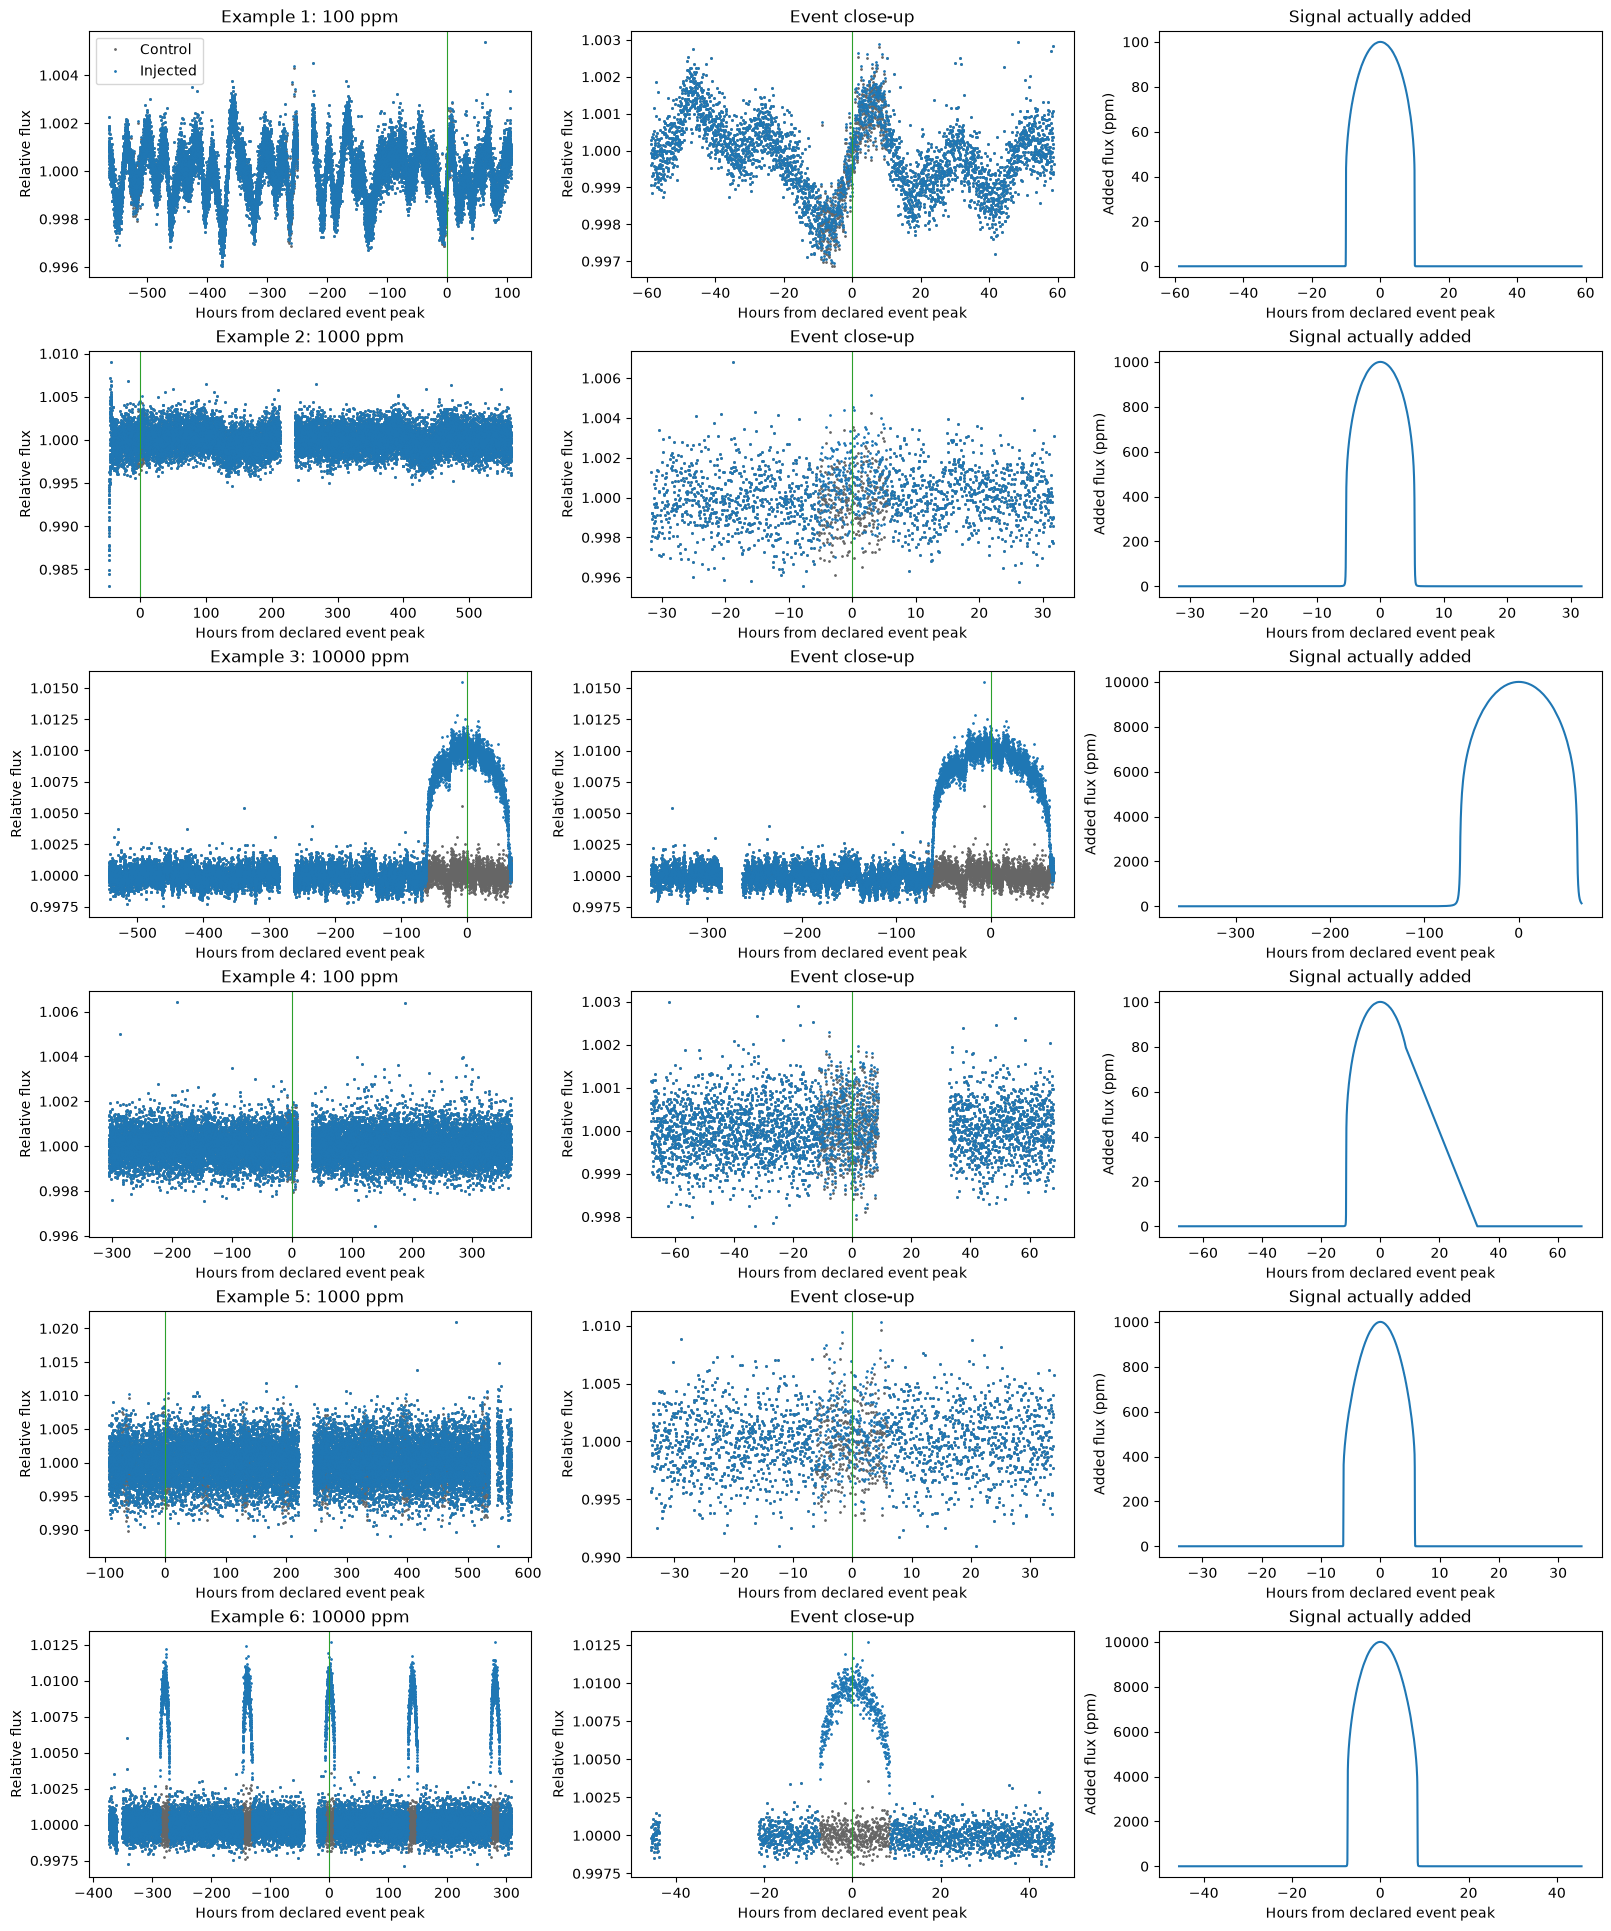

In [3]:
fig, axes = plt.subplots(len(cases), 3, figsize=(16, 3.2*len(cases)), squeeze=False,
                         layout='constrained')
for row, (event, sample, control, injected, finite, baseline, added) in enumerate(cases):
    hours = (control.time-event['time'])*24
    half_window = max(3*event['duration_days'], 4*np.median(control.exposure_seconds)/86400)*24
    near = finite & (np.abs(hours) <= half_window)
    full, zoom, signal = axes[row]
    for axis, mask in [(full, finite), (zoom, near)]:
        axis.plot(hours[mask], control.flux[mask]/baseline, '.', color='.4', ms=2, label='Control')
        axis.plot(hours[mask], injected.flux[mask]/baseline, '.', color='tab:blue', ms=2, label='Injected')
        axis.axvline(0, color='tab:green', lw=.8)
        axis.set_ylabel('Relative flux')
    full.set_title(f"Example {row+1}: {event['amplitude']*1e6:g} ppm")
    zoom.set_title('Event close-up')
    signal.plot(hours[near], added[near], color='tab:blue')
    signal.set(title='Signal actually added', ylabel='Added flux (ppm)')
    for axis in axes[row]:
        axis.set_xlabel('Hours from declared event peak')
axes[0,0].legend()
plt.show()
